In [1]:
# Updated for Spring 2026 EE300005

# Import all libraries

# TensorFlow is an open source machine learning library
import tensorflow as tf
import keras
# NumPy is a math library
import numpy as np
# Matplotlib is a graphing library
import matplotlib.pyplot as plt
# math is Python's math library
import math

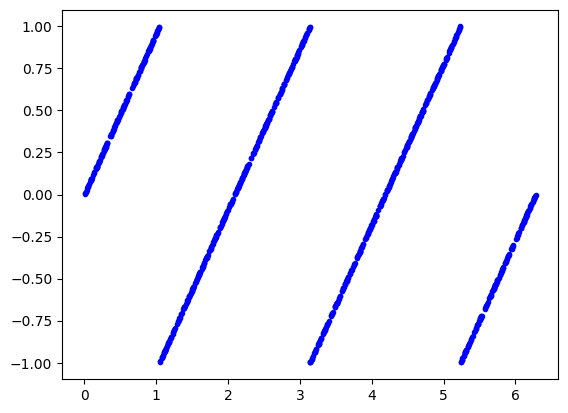

In [2]:
# We'll generate this many sample datapoints
SAMPLES = 1000

# Set a "seed" value, so we get the same random numbers each time we run this # notebook. Any number can be used here.
np.random.seed(1337)

# Generate a uniformly distributed set of random numbers in the range from # 0 to 2π, which covers a complete sine wave oscillation
x_values = np.random.uniform(low=0, high=2*math.pi, size=SAMPLES)

# Shuffle the values to guarantee they're not in order
np.random.shuffle(x_values)

# Calculate the corresponding sine values
y_values = 2 * ((3 * x_values) / (2 * np.pi) - np.floor((3 * x_values) / (2 * np.pi) + 0.5))

# Plot our data. The 'b.' argument tells the library to print blue dots.
plt.plot(x_values, y_values, 'b.')
plt.show()

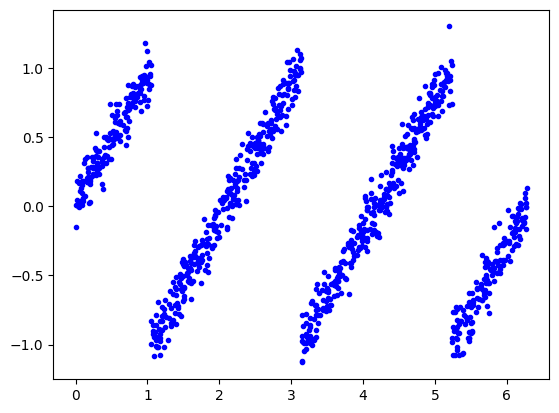

In [3]:
# Add some noise to sine values
y_values += 0.1 * np.random.randn(*y_values.shape)

# Plot our data. The 'b.' argument tells the library to print blue dots.
plt.plot(x_values, y_values, 'b.')
plt.show()

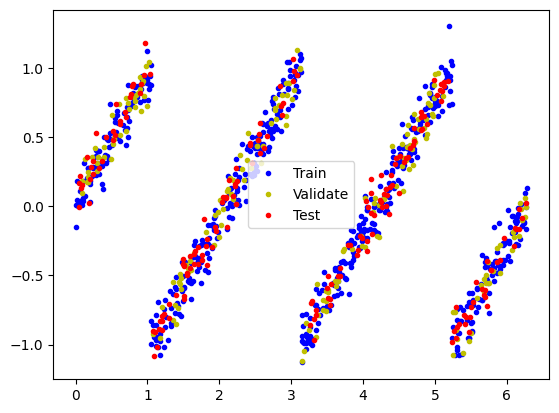

In [4]:
# We'll use 60% of our data for training and 20% for testing.
# The remaining 20% # will be used for validation.
# Calculate the indices of each section.
TRAIN_SPLIT = int(0.6 * SAMPLES)
TEST_SPLIT = int(0.2 * SAMPLES + TRAIN_SPLIT)

# Use np.split to chop our data into three parts.
# The second argument to np.split is an array of indices where the data will be
# split. We provide two indices, so the data will be divided into three chunks.
x_train, x_validate, x_test = np.split(x_values, [TRAIN_SPLIT, TEST_SPLIT])
y_train, y_validate, y_test = np.split(y_values, [TRAIN_SPLIT, TEST_SPLIT])

# Double check that our splits add up correctly
assert (x_train.size + x_validate.size + x_test.size) == SAMPLES

# Plot the data in each partition in different colors:
plt.plot(x_train, y_train, 'b.', label="Train")
plt.plot(x_validate, y_validate, 'y.', label="Validate")
plt.plot(x_test, y_test, 'r.', label="Test")
plt.legend()
plt.show()

In [5]:
# We'll use Keras to create a simple model architecture
from keras import layers
model_1 = keras.Sequential()

# First layer takes a scalar input and feeds it through 16 "neurons." The
# neurons decide whether to activate based on the 'relu' activation function.
model_1.add(layers.Dense(16, activation='relu', input_shape=(1,)))

# Final layer is a single neuron, since we want to output a single value
model_1.add(layers.Dense(1))
# Compile the model using a standard optimizer and loss function for regression
model_1.compile(optimizer='rmsprop', loss='mse', metrics=['mae'])

# Print a summary of the model's architecture
model_1.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49 (196.00 B)

 Trainable params: 49 (196.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_1 = model_1.fit(x_train, y_train, epochs=1000, batch_size=16,
                         validation_data=(x_validate, y_validate))

Epoch 1/1000
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.5506 - mae: 0.6356 - val_loss: 0.5402 - val_mae: 0.6501
Epoch 2/1000
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5043 - mae: 0.6267 - val_loss: 0.5171 - val_mae: 0.6379
Epoch 3/1000
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5001 - mae: 0.6259 - val_loss: 0.5147 - val_mae: 0.6355
Epoch 4/1000
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4982 - mae: 0.6237 - val_loss: 0.5089 - val_mae: 0.6314
Epoch 5/1000
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4960 - mae: 0.6224 - val_loss: 0.5136 - val_mae: 0.6330
Epoch 6/1000
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4946 - mae: 0.6195 - val_loss: 0.5026 - val_mae: 0.6261
Epoch 7/1000
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4941 - mae: 0.6206 - val_loss: 0.5049 - val_mae: 0.6263
Epoch 8/1000
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4921 - mae: 0.6187 - val_loss: 0.5090 - val_mae: 0.6278
Epoch 9/1000
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - lo

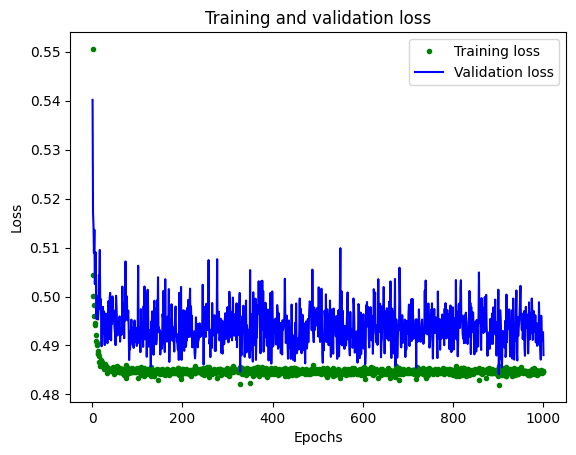

In [ ]:
loss = history_1.history['loss']
val_loss = history_1.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'g.', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

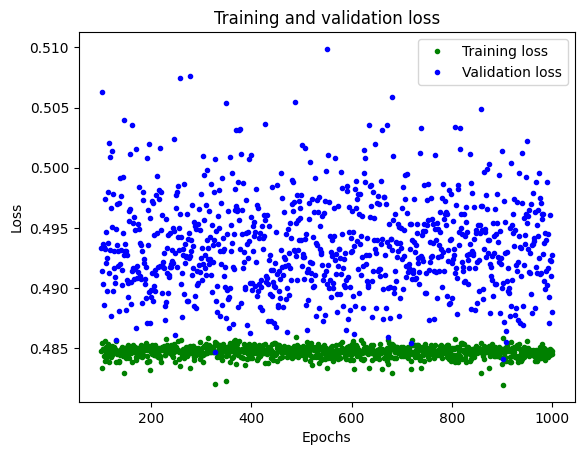

In [ ]:
SKIP = 100
plt.plot(epochs[SKIP:], loss[SKIP:], 'g.', label='Training loss')
plt.plot(epochs[SKIP:], val_loss[SKIP:], 'b.', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


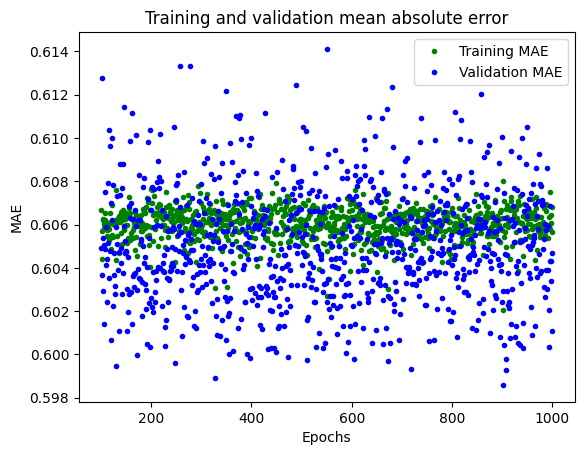

In [ ]:
# Draw a graph of mean absolute error, which is another way of # measuring the amount of error in the prediction.
mae = history_1.history['mae']
val_mae = history_1.history['val_mae']

plt.plot(epochs[SKIP:], mae[SKIP:], 'g.', label='Training MAE')
plt.plot(epochs[SKIP:], val_mae[SKIP:], 'b.', label='Validation MAE')
plt.title('Training and validation mean absolute error')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()
plt.show()

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


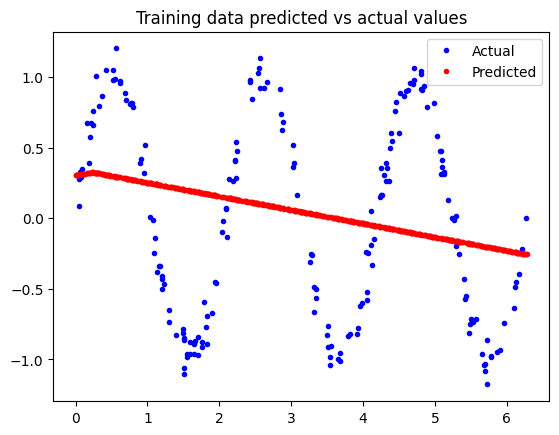

In [ ]:
# Use the model to make predictions from our validation data
predictions = model_1.predict(x_train)

# Plot the predictions along with the test data
plt.clf()
plt.title('Training data predicted vs actual values')
plt.plot(x_test, y_test, 'b.', label='Actual')
plt.plot(x_train, predictions, 'r.', label='Predicted')
plt.legend()
plt.show()

In [18]:
model_2 = tf.keras.Sequential()
# First layer takes a scalar input and feeds it through 16 "neurons." The
# neurons decide whether to activate based on the 'relu' activation function.
model_2.add(layers.Dense(128, activation='relu', input_shape=(1,)))

# The new second layer may help the network learn more complex representations
model_2.add(layers.Dense(128, activation='relu'))

# Khangal note: added in two more layer, increased neuron to 128.
model_2.add(layers.Dense(128, activation='relu'))

model_2.add(layers.Dense(128, activation='relu'))

# Final layer is a single neuron, since we want to output a single value
model_2.add(layers.Dense(1))

# Compile the model using a standard optimizer and loss function for regression
model_2.compile(optimizer='rmsprop', loss='mse', metrics=['mae']) # Show a summary of the model
model_2.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                │ (None, 128)            │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,921 (195.00 KB)

 Trainable params: 49,921 (195.00 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history_2 = model_2.fit(x_train, y_train, epochs=600, batch_size=16,
                         validation_data=(x_validate, y_validate))

Epoch 1/600
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3549 - mae: 0.5031 - val_loss: 0.3347 - val_mae: 0.5004
Epoch 2/600
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3407 - mae: 0.4918 - val_loss: 0.3190 - val_mae: 0.4814
Epoch 3/600
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3345 - mae: 0.4851 - val_loss: 0.3128 - val_mae: 0.4685
Epoch 4/600
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3294 - mae: 0.4779 - val_loss: 0.3429 - val_mae: 0.4877
Epoch 5/600
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3215 - mae: 0.4711 - val_loss: 0.3051 - val_mae: 0.4620
Epoch 6/600
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3165 - mae: 0.4664 - val_loss: 0.2919 - val_mae: 0.4487
Epoch 7/600
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3091 - mae: 0.4562 - val_loss: 0.2794 - val_mae: 0.4341
Epoch 8/600
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3143 - mae: 0.4482 - val_loss: 0.2695 - val_mae: 0.4245
Epoch 9/600
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.296

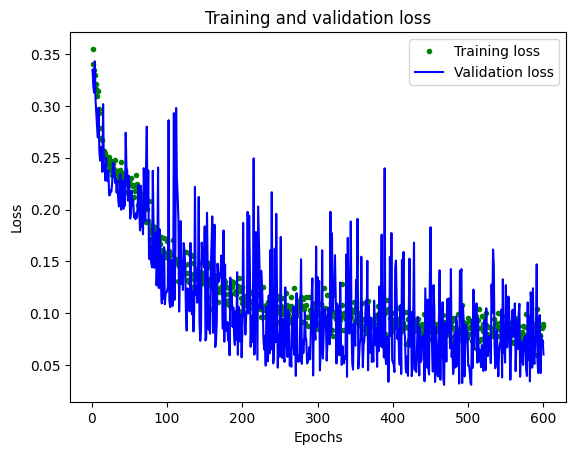

In [20]:
loss = history_2.history['loss']
val_loss = history_2.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'g.', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

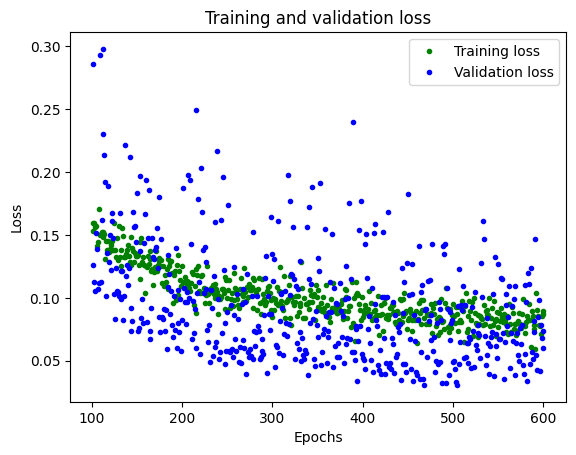

In [21]:
# Exclude the first few epochs so the graph is easier to read
SKIP = 100
plt.clf()
plt.plot(epochs[SKIP:], loss[SKIP:], 'g.', label='Training loss')
plt.plot(epochs[SKIP:], val_loss[SKIP:], 'b.', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

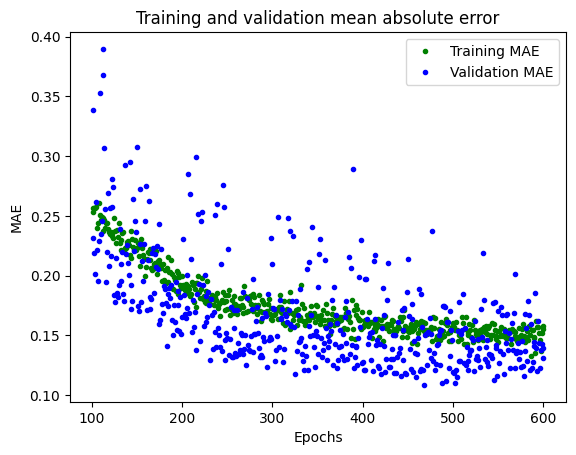

In [22]:
plt.clf()
# Draw a graph of mean absolute error, which is another way of # measuring the amount of error in the prediction.
mae = history_2.history['mae']
val_mae = history_2.history['val_mae']
plt.plot(epochs[SKIP:], mae[SKIP:], 'g.', label='Training MAE')
plt.plot(epochs[SKIP:], val_mae[SKIP:], 'b.', label='Validation MAE')
plt.title('Training and validation mean absolute error')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()
plt.show()

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0430 - mae: 0.1113 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


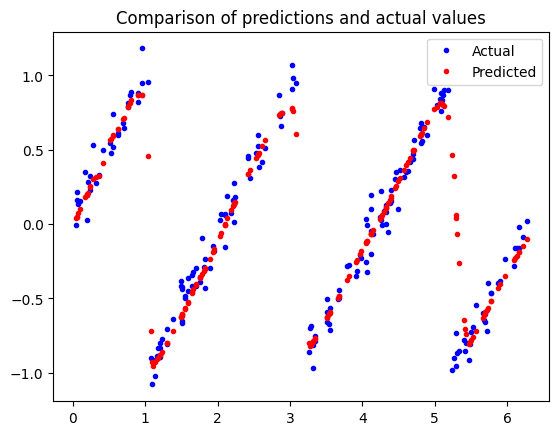

In [23]:
# Calculate and print the loss on our test dataset
loss = model_2.evaluate(x_test, y_test)
# Make predictions based on our test dataset
predictions = model_2.predict(x_test)
# Graph the predictions against the actual values
plt.clf()
plt.title('Comparison of predictions and actual values')
plt.plot(x_test, y_test, 'b.', label='Actual')
plt.plot(x_test, predictions, 'r.', label='Predicted')
plt.legend()
plt.show()

In [24]:
# Convert the model to the TensorFlow Lite format (as simple as possible)
converter = tf.lite.TFLiteConverter.from_keras_model(model_2)
tflite_model = converter.convert()

# Save the model to disk for use on colab or tflite python libraries
with open('sine_model.tflite', 'wb') as f:
	f.write(tflite_model)

Saved artifact at '/tmp/tmp9eb711pa'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='keras_tensor_33')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  132886580307792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580307600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580306064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580306256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580307984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580305488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580305680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580307216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580304912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580306832: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [25]:
# Convert the model to the TensorFlow Lite format
converter = tf.lite.TFLiteConverter.from_keras_model(model_2)

# Enable default optimizations (includes quantization)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Enforce integer-only quantization
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

# Provide representative dataset for calibration
def representative_dataset_generator():
  for value in x_train:
    yield [np.array(value, dtype=np.float32, ndmin=2)]

converter.representative_dataset = representative_dataset_generator

# Convert (may show warnings about fallback - this is expected)
tflite_model = converter.convert()

# Save the model to disk
with open('sine_model_quant.tflite', 'wb') as f:
  f.write(tflite_model)

Saved artifact at '/tmp/tmpz6jkj48s'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='keras_tensor_33')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  132886580307792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580307600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580306064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580306256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580307984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580305488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580305680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580307216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580304912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132886580306832: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


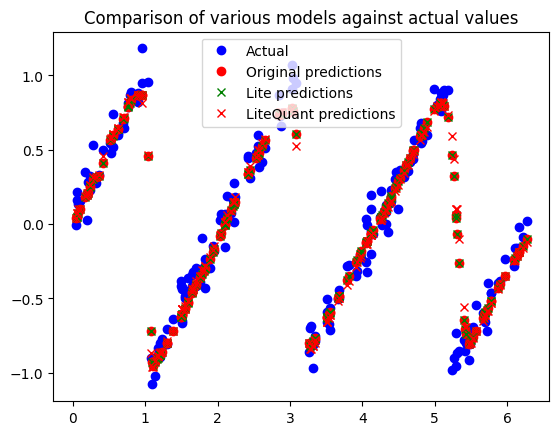

In [26]:
# Instantiate an interpreter
sine_model = tf.lite.Interpreter('sine_model.tflite')
sine_model_quant = tf.lite.Interpreter('sine_model_quant.tflite')

# load the parameters to convert to and from the quantized data type
input_scale, input_zero_point = sine_model_quant.get_input_details()[0]["quantization"]
output_scale, output_zero_point = sine_model_quant.get_output_details()[0]["quantization"]

# Allocate memory for each model
sine_model.allocate_tensors()
sine_model_quant.allocate_tensors()

# Get indexes of the input and output tensors
sine_model_input_index  = sine_model.get_input_details() [0]["index"]
sine_model_output_index = sine_model.get_output_details()[0]["index"]

sine_model_quant_input_index  = sine_model_quant.get_input_details() [0]["index"]
sine_model_quant_output_index = sine_model_quant.get_output_details()[0]["index"]

# Create array to store the results
sine_model_predictions = []
sine_model_quant_predictions = []

# Run each model's interpreter for each value and store the results in arrays
for x_value in x_test:
  # Create a 2D tensor wrapping the current x value
  x_value_tensor = tf.convert_to_tensor([[x_value]], dtype=np.float32)
  x_value_quant = x_value / input_scale + input_zero_point
  x_value_quant = x_value_quant.astype(np.int8)
  x_value_tensorInt8 = tf.convert_to_tensor([[x_value_quant]], dtype=np.int8)

  # Write the value to the input tensor
  sine_model.set_tensor(sine_model_input_index, x_value_tensor)
  # Run inference
  sine_model.invoke()
  # Read the prediction from the output tensor
  sine_model_predictions.append(sine_model.get_tensor(sine_model_output_index)[0])

  # Ditto for the quant model
  sine_model_quant.set_tensor(sine_model_quant_input_index, x_value_tensorInt8)
  sine_model_quant.invoke()
  sine_model_quant_pred = sine_model_quant.get_tensor(sine_model_quant_output_index)[0]
  sine_model_quant_pred = sine_model_quant_pred.astype(np.float32)
  sine_model_quant_pred = (sine_model_quant_pred - output_zero_point) * output_scale
  sine_model_quant_predictions.append(sine_model_quant_pred)

# See how they line up with the data
plt.clf()
plt.title('Comparison of various models against actual values')
plt.plot(x_test, y_test, 'bo', label='Actual')
plt.plot(x_test, predictions, 'ro', label='Original predictions')
plt.plot(x_test, sine_model_predictions, 'gx', label='Lite predictions')
plt.plot(x_test, sine_model_quant_predictions, 'rx', label='LiteQuant predictions')
plt.legend()
plt.show()

In [27]:
# Load both models
with open('sine_model.tflite', 'rb') as f:
    float_model = f.read()

with open('sine_model_quant.tflite', 'rb') as f:
    quant_model = f.read()

print(f"Float32 size: {len(float_model)} bytes")
print(f"INT8 size: {len(quant_model)} bytes")
print(f"Difference: {len(quant_model) - len(float_model)} bytes")
print(f"Ratio: {len(quant_model) / len(float_model):.2%}")

Float32 size: 202380 bytes
INT8 size: 66864 bytes
Difference: -135516 bytes
Ratio: 33.04%


In [ ]:
# Raspberry Pi Script - Copy this, uncomment it and run it on your Pi

# import math
# import numpy as np
# import plotext as plt
# from tflite_runtime.interpreter import Interpreter
# from pathlib import Path
# import time

# path = "sine_model_quant.tflite"

# if not Path(path).exists():
#     raise FileNotFoundError(f"Model not found: {path}")

# model_size = Path(path).stat().st_size
# print(f"Model size: {model_size} bytes ({model_size/1024:.2f} KB)")

# interp = Interpreter(model_path=path)
# interp.allocate_tensors()
# in_det, out_det = interp.get_input_details(), interp.get_output_details()

# # Get quantization parameters
# in_scale, in_zero = in_det[0]['quantization']
# out_scale, out_zero = out_det[0]['quantization']

# # Warmup
# for _ in range(10):
#     x_in = np.array([[int(0/in_scale + in_zero)]], dtype=np.int8)
#     interp.set_tensor(in_det[0]['index'], x_in)
#     interp.invoke()

# # Prepare test data
# x_vals = np.arange(0, 2*math.pi, 0.05)
# y_true = np.sin(x_vals)
# y_pred = []
# times = []

# # Benchmark individual inferences
# for x in x_vals:
#     x_in = np.array([[int(x/in_scale + in_zero)]], dtype=np.int8)
#     interp.set_tensor(in_det[0]['index'], x_in)

#     start = time.perf_counter()
#     interp.invoke()
#     end = time.perf_counter()

#     y = interp.get_tensor(out_det[0]['index'])[0][0]
#     y_pred.append((y - out_zero) * out_scale)
#     times.append((end - start) * 1000)

# y_pred = np.array(y_pred)
# times = np.array(times)

# # Performance metrics
# print(f"\n=== Timing Statistics ===")
# print(f"  Mean: {np.mean(times):.4f} ms (typical latency)")
# print(f"  Median: {np.median(times):.4f} ms (middle value)")
# print(f"  Std: {np.std(times):.4f} ms (consistency)")
# print(f"  Min: {np.min(times):.4f} ms (best case)")
# print(f"  Max: {np.max(times):.4f} ms (worst case)")
# print(f"  Inferences/sec: {1000/np.mean(times):.0f} (throughput)")

# # Accuracy metrics
# mae = np.mean(np.abs(y_pred - y_true))
# mse = np.mean((y_pred - y_true)**2)
# rmse = np.sqrt(mse)
# max_error = np.max(np.abs(y_pred - y_true))

# print(f"\n=== Accuracy Metrics ===")
# print(f"  MAE: {mae:.6f} (avg absolute error)")
# print(f"  RMSE: {rmse:.6f} (penalizes large errors)")
# print(f"  Max Error: {max_error:.6f} (worst case error)")

# print(f"\n=== Design Tradeoffs ===")
# print(f"  Speed: {1000/np.mean(times):.0f} inferences/sec")
# print(f"  Size: {model_size/1024:.1f} KB")
# print(f"  Accuracy: MAE={mae:.6f}")

# # Plot comparison
# plt.plot(x_vals, y_pred, label="Quantized Model")
# plt.plot(x_vals, y_true, label="True Sine")
# plt.title("Quantized Model vs True Sine")
# plt.xlabel("Input (radians)")
# plt.ylabel("Output")
# plt.show()